# Synthetic Control — California SB 3 and Leisure-and-Hospitality Employment

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** FRED current series, 2010-01 to 2019-12 (the retrieval is the vintage; see Data Provenance)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a series is
missing, an identifier does not resolve, or the donor pool recomputed from the wage schedule differs from the
one fixed in the plan, the notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/C04_pap.md`) committed before the notebook was run. The plan
was amended once, after the first two executions had stopped and before any gap, effect or placebo ratio was displayed;
the section *Amendment provenance* says exactly what was and was not seen. The notebook is bound to the amended file by
its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** why, with one treated unit, the counterfactual is a weighted average of untreated units, and read the
   weights as the argument.
2. **Construct** a synthetic control with simplex-constrained weights fitted on the pre-period, and judge its pre-period
   fit.
3. **Run** permutation inference by treating every donor as the treated unit in turn, and read a rank and a p-value
   whose smallest possible value depends on the number of donors.
4. **Test** the design with an in-time placebo, a date at which nothing happened.
5. **State** what the donor pool and the first-of-several nature of the policy do to what the estimate means.

## Prerequisites

**Knowledge.** Constrained least squares; the idea of a counterfactual; why a pre-period fit is necessary but not sufficient.

**Setup.** A free FRED API key from <https://fred.stlouisfed.org/docs/api/api_key.html>, supplied by you as the
environment variable `FRED_API_KEY`, or as a line `FRED_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`.
The key is read at runtime and is never printed or written into this notebook's output.

**Packages.** `pandas`, `numpy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (its
`methods.synth` module holds the estimators).

**Prior notebooks.** C01 introduces the identification contract; C03 introduces the minimum-wage schedule used for the donors.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `CALEIH` | FRED, *All Employees: Leisure and Hospitality in California*, thousands, seasonally adjusted | outcome (treated unit) |
| `<ST>LEIH` for 21 donor states | FRED, same measure for each state | donor outcomes |
| `<ST>UR`, `<ST>NA` | FRED, unemployment rate and total nonfarm employment | covariates |
| `data/policy/minimum_wage/state_schedule.csv` | U.S. Department of Labor, January-1 state minimum wages | the donor rule |

Every series identifier is checked against FRED's `series` endpoint (title, units, seasonal adjustment, coverage)
before any observation is used. FRED revises its series and this notebook uses the current one, so the retrieval is
the vintage: naming a window pins the reference period, not the revision. (The provenance records say "pinned" because
the window is pinned at both ends; the notebook's metadata says the vintage is not pinned because FRED rewrites history.
Both are true.) Each series' request is recorded in `provenance/`, bound to the plan's SHA-256, and so is the Census
state-code list used to name the donors.

## Design and identification

**Estimand.** The average gap, over January 2017 to December 2019, between California's leisure-and-hospitality
employment and a weighted average of states with no scheduled minimum-wage increase, in thousands of jobs and per
cent of the synthetic series. Every series is fitted as an index of its own pre-period mean (see the amendment note in
Limitations). The policy is SB 3, chaptered April 2016; the first scheduled increase took effect
1 January 2017. The window ends before the pandemic.

**Assumption.** The donor combination that tracks California before 2017 would have continued to track it, and no
donor was itself affected. Neither can be tested. A good pre-period fit is necessary, not sufficient.

**Decision rule, fixed in the plan.** An effect counts as detected only if the permutation p-value is at most 0.10.
The design counts as credible only if the pre-period fit and the in-time placebo pass; otherwise the gap is descriptive.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import synth
from krl_tutorials_data.provenance import DataProvenance
from krl_tutorials_data.sources import FRED_HOST, DataAccessError, fetch_fred, load_key

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C04_ca_minimum_wage_synth"
PAP = NB_DIR / "pap" / "C04_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

START, END = "2010-01-01", "2019-12-01"
N_PRE, N_POST = 84, 36                      # 2010-01..2016-12, 2017-01..2019-12
PLACEBO_PRE = 48                            # in-time placebo date: 2014-01
COVARIATE_INDEX_POINTS, COVARIATE_WEIGHT = 5.0, 10.0
FIT_LIMIT_PCT, PERMUTATION_ALPHA = 3.0, 0.10
TARGET = "CALEIH"
ADDED = "not pre-specified (added after review, 2026-10-23)"
PLAN_DONORS = ["AL", "GA", "ID", "IN", "IA", "KS", "KY", "LA", "MS", "NH", "NC", "ND", "OK", "PA", "SC", "TN",
               "TX", "UT", "VA", "WI", "WY"]

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"window            : {START} to {END}; pre-period {N_PRE} months, post-period {N_POST} months")

pre-analysis plan : projects/09-causal-identification/C04_ca_minimum_wage_synth/pap/C04_pap.md
plan SHA-256      : bbb4b7a90571288f1d6d473c87014596a0cd7f403a36d3b288cd16c67a5e57df
window            : 2010-01-01 to 2019-12-01; pre-period 84 months, post-period 36 months


### The donor pool, recomputed from the wage schedule

A state is a donor if its effective minimum wage is the same on 1 January of every year from 2015 to 2020. The rule is
applied to the repository's schedule here and the result must equal the list fixed in the plan.

In [2]:
schedule = pd.read_csv(REPO_ROOT / "data" / "policy" / "minimum_wage" / "state_schedule.csv")
window = schedule[schedule["year"].between(2015, 2020) & (schedule["jurisdiction"] != "Federal (FLSA)")].copy()
window["effective"] = np.where(window["rate_low"].isna(), 7.25, np.maximum(window["rate_low"], 7.25))
effective = window.pivot(index="jurisdiction", columns="year", values="effective")
constant = effective.index[effective.nunique(axis=1) == 1].tolist()

reply = requests.get("https://www2.census.gov/geo/docs/reference/state.txt", timeout=60,
                     headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
lines = [row.split("|") for row in reply.text.strip().splitlines()[1:]]
postal = {name: code for _, code, name, _ in lines if code not in ("PR", "VI", "GU", "AS", "MP", "UM")}
donors = sorted(postal[name] for name in constant if name in postal and name != "California")
print(f"states whose effective rate is constant 2015-2020, excluding California: {len(donors)}")
print(", ".join(donors))
if donors != sorted(PLAN_DONORS):
    raise SystemExit("The donor pool recomputed from the schedule differs from the plan: " +
                     f"extra {sorted(set(donors) - set(PLAN_DONORS))}, missing {sorted(set(PLAN_DONORS) - set(donors))}")
print("The recomputed pool equals the pool fixed in the plan.")
print("California's rows in the schedule file:")
print(schedule[(schedule["jurisdiction"] == "California") & schedule["year"].between(2013, 2019)][["year", "rate_as_published", "rate_low"]].to_string(index=False))
print("the file records 1 January values only, so a step made part-way through a year is not visible in it, and its 2017 row is not the 2017 increase")
FIPS_PROVENANCE = DataProvenance.build(
    pinned=False, source_name="U.S. Census Bureau", dataset="State FIPS codes, names and postal abbreviations",
    vintage="retrieval", endpoint="https://www2.census.gov/geo/docs/reference/state.txt",
    variables={"STUSAB": "postal abbreviation", "STATE_NAME": "name"},
    payload=reply.content, row_count=len(lines), column_count=4,
    notes=("A reference list used only to map state names in the wage schedule to postal abbreviations for the donor series.",),
)
_ = FIPS_PROVENANCE.with_pap(PAP).write(NB_DIR / "provenance" / "c04_state_codes.json")

states whose effective rate is constant 2015-2020, excluding California: 21
AL, GA, IA, ID, IN, KS, KY, LA, MS, NC, ND, NH, OK, PA, SC, TN, TX, UT, VA, WI, WY
The recomputed pool equals the pool fixed in the plan.
California's rows in the schedule file:
 year rate_as_published  rate_low
 2013              8.00       8.0
 2014              9.00       9.0
 2015              9.00       9.0
 2016             10.00      10.0
 2017             10.00      10.0
 2018             11.00      11.0
 2019             12.00      12.0
the file records 1 January values only, so a step made part-way through a year is not visible in it, and its 2017 row is not the 2017 increase


### Checking the series identifiers

Before any observation is read, each identifier is looked up on FRED's `series` endpoint, and the title, units, seasonal
adjustment, frequency and coverage are checked. A series that does not resolve, or is not seasonally adjusted monthly
data covering the window, stops the notebook.

In [3]:
IDS = ["CALEIH"] + [f"{s}LEIH" for s in donors] + [f"{s}UR" for s in ["CA"] + donors] + [f"{s}NA" for s in ["CA"] + donors]
key = load_key("FRED_API_KEY")


def series_info(series_id: str) -> dict:
    """The series endpoint's description of one identifier, retrying a throttled request."""
    for pause in (0, 5, 15, 45):
        clock.sleep(pause)
        reply = requests.get(f"{FRED_HOST}/series", timeout=60,
                             params={"series_id": series_id, "api_key": key, "file_type": "json"})
        if reply.status_code == 200:
            return reply.json()["seriess"][0]
        if reply.status_code not in (429, 500, 502, 503, 504):
            raise SystemExit(f"FRED does not recognise the identifier {series_id} (HTTP {reply.status_code}).")
    raise SystemExit(f"FRED kept refusing the lookup of {series_id}.")


info = pd.DataFrame([{k: series_info(i)[k] for k in
                      ("id", "title", "units_short", "seasonal_adjustment_short", "frequency_short",
                       "observation_start", "observation_end")} for i in IDS])
print(info[info["id"] == "CALEIH"].T.to_string(header=False))
bad = info[(info["seasonal_adjustment_short"] != "SA") | (info["frequency_short"] != "M")
           | (info["observation_start"] > START) | (info["observation_end"] < END)]
print(f"{len(info)} identifiers resolved; not seasonally adjusted monthly with full coverage: {len(bad)}")
if len(bad):
    raise SystemExit("Some series do not match the plan: " + ", ".join(bad["id"]))
print("Titles in use:", "; ".join(sorted({t.rsplit(' in ', 1)[0] for t in info['title']})))

id                                                                       CALEIH
title                      All Employees: Leisure and Hospitality in California
units_short                                                   Thous. of Persons
seasonal_adjustment_short                                                    SA
frequency_short                                                               M
observation_start                                                    1990-01-01
observation_end                                                      2026-09-01
66 identifiers resolved; not seasonally adjusted monthly with full coverage: 0
Titles in use: All Employees: Leisure and Hospitality; All Employees: Total Nonfarm; Unemployment Rate


### Retrieving the series

One request per series, for the window in the plan. Each observation is a published number; nothing is filled or
interpolated, and a series with a missing month stops the notebook.

In [4]:
values, records = {}, {}
try:
    for series_id in IDS:
        for pause in (0, 5, 15, 45):
            clock.sleep(pause)
            try:
                frame, prov = fetch_fred(series_id=series_id, start=START, end=END, frequency="m", units="lin")
                break
            except DataAccessError as exc:
                if "HTTP 5" not in str(exc) and "HTTP 429" not in str(exc):
                    raise
        else:
            raise SystemExit(f"FRED kept refusing {series_id}")
        values[series_id] = frame.set_index("date")["value"].astype(float)
        records[series_id] = prov
        prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c04_fred_{series_id}.json")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

panel = pd.DataFrame(values)
months = pd.date_range(START, END, freq="MS")
panel = panel.reindex(months)
if panel.isna().any().any() or len(panel) != N_PRE + N_POST:
    raise SystemExit("A series has a missing month in the window; nothing is filled.")
print(f"series retrieved: {panel.shape[1]}; months: {len(panel)} ({panel.index[0]:%Y-%m} to {panel.index[-1]:%Y-%m})")
print(records["CALEIH"].render())

series retrieved: 66; months: 120 (2010-01 to 2019-12)
Source      : Federal Reserve Bank of St. Louis - FRED series CALEIH
Vintage     : 2010-01-01 to 2019-12-01, current revision  (pinned)
Endpoint    : https://api.stlouisfed.org/fred/series/observations
Retrieved   : 2026-10-23T20:56:23+00:00
Shape       : 120 rows x 2 cols
Payload hash: 34a83f8bad10a579...  (response-bytes)
Data mode   : EMPIRICAL
Variables   :
              CALEIH           FRED CALEIH, frequency=m, units=lin
Limitations :
              - Window is pinned at both ends; an open end would change every derived number on re-run.
              - 0 observation(s) were published as the missing sentinel '.' and became NaN before any arithmetic.
              - Current revision: FRED rewrites history at each revision and rebasing, so these values differ from what was published earlier. Pass `vintage` to recover a historical publication.


In [5]:
"""Indexed outcomes and two standardised covariates."""
leih = panel[["CALEIH"] + [f"{s}LEIH" for s in donors]]


def indexed(base_months: int) -> tuple[np.ndarray, np.ndarray]:
    """Each series as 100 x value / its own mean over the first ``base_months`` months.

    California exceeds every donor in every pre-period month, so a fit in levels cannot match it
    (see the amendment to the plan). An index puts every unit on the scale of its own history.
    """
    index = 100.0 * leih / leih.iloc[:base_months].mean()
    return index["CALEIH"].to_numpy(), index.drop(columns="CALEIH").to_numpy()


def covariates(upto: int) -> tuple[np.ndarray, np.ndarray]:
    """Mean unemployment rate and mean leisure-and-hospitality share, over the first ``upto`` months.

    Standardised across California and the donors, then scaled so that one standard deviation counts
    like a 5-point gap in an index whose base is 100.
    """
    units = ["CA"] + donors
    unemployment = np.array([panel[f"{s}UR"].iloc[:upto].mean() for s in units])
    share = np.array([(100 * panel[f"{s}LEIH"].iloc[:upto] / panel[f"{s}NA"].iloc[:upto]).mean() for s in units])
    rows = [COVARIATE_INDEX_POINTS * (raw - raw.mean()) / raw.std(ddof=1) for raw in (unemployment, share)]
    stacked = np.vstack(rows)
    return stacked[:, 0], stacked[:, 1:]


level_ca = panel["CALEIH"].to_numpy()
ca, pool = indexed(N_PRE)
cov_ca, cov_donors = covariates(N_PRE)
CA_MEAN = float(level_ca[:N_PRE].mean())
print(f"California: pre-period mean employment {CA_MEAN:,.0f} thousand (index 100)")
months_above = int((leih["CALEIH"].iloc[:N_PRE].to_numpy() > leih.drop(columns="CALEIH").iloc[:N_PRE].max(axis=1).to_numpy()).sum())
print(f"pre-period months in which California exceeds every donor in levels: {months_above} of {N_PRE}")
print(f"covariate rows (standardised, in index points): California {np.round(cov_ca, 2)}")
print(f"largest donor's pre-period mean employment in levels: {leih.drop(columns='CALEIH').iloc[:N_PRE].mean().max():,.0f} thousand, against California's {CA_MEAN:,.0f}")

California: pre-period mean employment 1,685 thousand (index 100)
pre-period months in which California exceeds every donor in levels: 84 of 84
covariate rows (standardised, in index points): California [8.64 5.62]
largest donor's pre-period mean employment in levels: 1,142 thousand, against California's 1,685


### The synthetic California

Weights on the 21 donors, chosen to make the weighted average track California through 2016 on the monthly outcomes and
the two covariates. The weights table is the argument: it says which states stand in for California and how much.

state  weight
   GA  0.6829
   SC  0.3171
weights sum to 1.000000; donors with positive weight: 2 of 21
pre-period RMSPE  : 1.28 index points (1.28% of mean pre-period employment)
post-period RMSPE : 0.80 index points; ratio 0.62
mean post-period gap, California minus synthetic: +9.0 thousand jobs (+0.47% of the synthetic series)


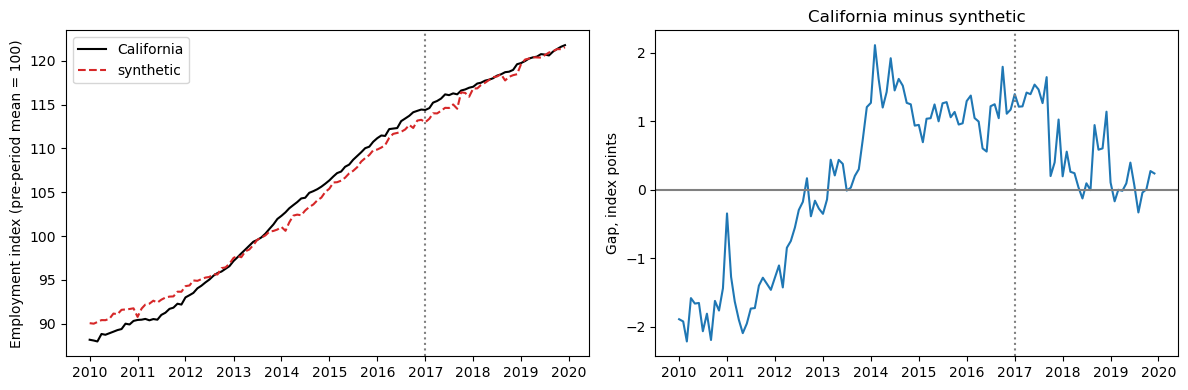

In [6]:
fit = synth.synthetic_control(ca, pool, n_pre=N_PRE, covariates_treated=cov_ca,
                              covariates_donors=cov_donors, covariate_weight=COVARIATE_WEIGHT)
table = pd.DataFrame({"state": donors, "weight": fit.weights}).sort_values("weight", ascending=False)
print(table[table["weight"] > 1e-4].round(4).to_string(index=False))
print(f"weights sum to {fit.weights.sum():.6f}; donors with positive weight: {int((fit.weights > 1e-4).sum())} of {len(donors)}")

def to_thousands(index_points: float) -> float:
    """Convert a gap in index points to thousands of jobs at California's pre-period mean."""
    return index_points / 100.0 * CA_MEAN


post_gap = fit.gap[N_PRE:]
mean_gap = to_thousands(float(post_gap.mean()))
mean_pct = float(100 * (post_gap / fit.synthetic[N_PRE:]).mean())
pre_pct = float(fit.pre_rmspe)                      # index points = per cent of the pre-period mean
print(f"pre-period RMSPE  : {fit.pre_rmspe:.2f} index points ({pre_pct:.2f}% of mean pre-period employment)")
print(f"post-period RMSPE : {fit.post_rmspe:.2f} index points; ratio {fit.rmspe_ratio:.2f}")
print(f"mean post-period gap, California minus synthetic: {mean_gap:+,.1f} thousand jobs ({mean_pct:+.2f}% of the synthetic series)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(panel.index, ca, color="black", label="California")
axes[0].plot(panel.index, fit.synthetic, color="tab:red", linestyle="--", label="synthetic")
axes[0].axvline(panel.index[N_PRE], color="grey", linestyle=":")
axes[0].set_ylabel("Employment index (pre-period mean = 100)")
axes[0].legend()
axes[1].plot(panel.index, fit.gap, color="tab:blue")
axes[1].axhline(0, color="grey")
axes[1].axvline(panel.index[N_PRE], color="grey", linestyle=":")
axes[1].set_ylabel("Gap, index points")
axes[1].set_title("California minus synthetic")
plt.tight_layout()
plt.show()

In [7]:
"""Sensitivity, beside the headline: outcomes only, and each weighted donor dropped in turn."""
plain = synth.synthetic_control(ca, pool, n_pre=N_PRE)
print(f"outcomes only : mean post gap {to_thousands(plain.gap[N_PRE:].mean()):+,.1f} thousand, pre-period RMSPE {plain.pre_rmspe:.2f} index points")

loo = []
for j in np.flatnonzero(fit.weights > 1e-4):
    keep = np.delete(np.arange(len(donors)), j)
    refit = synth.synthetic_control(ca, pool[:, keep], n_pre=N_PRE,
                                    covariates_treated=cov_ca, covariates_donors=cov_donors[:, keep],
                                    covariate_weight=COVARIATE_WEIGHT)
    loo.append({"dropped": donors[j], "mean post gap": to_thousands(refit.gap[N_PRE:].mean()), "pre RMSPE": refit.pre_rmspe})
loo = pd.DataFrame(loo)
print(loo.round(2).to_string(index=False))
print(f"leave-one-out range of the mean post gap: [{loo['mean post gap'].min():+,.1f}, {loo['mean post gap'].max():+,.1f}] thousand")

outcomes only : mean post gap -6.5 thousand, pre-period RMSPE 0.40 index points
dropped  mean post gap  pre RMSPE
     GA          29.28       1.73
     SC          15.48       1.12
leave-one-out range of the mean post gap: [+15.5, +29.3] thousand


In [8]:
"""not pre-specified (added after review, 2026-10-23): predictor balance, and how far the sign of the gap depends on the specification."""
print(ADDED)
def raw_covariates(unit: str) -> tuple[float, float]:
    """Pre-period mean unemployment rate and leisure-and-hospitality share of nonfarm employment, in per cent."""
    return (float(panel[f"{unit}UR"].iloc[:N_PRE].mean()),
            float((100 * panel[f"{unit}LEIH"].iloc[:N_PRE] / panel[f"{unit}NA"].iloc[:N_PRE]).mean()))

ca_raw = np.array(raw_covariates("CA"))
donor_raw = np.array([raw_covariates(s) for s in donors])
bal = pd.DataFrame({"California": ca_raw, "synthetic": fit.weights @ donor_raw,
                    "donor minimum": donor_raw.min(axis=0), "donor maximum": donor_raw.max(axis=0)},
                   index=["unemployment rate, %", "leisure and hospitality share of nonfarm, %"])
bal["California inside the donor range"] = (ca_raw >= donor_raw.min(axis=0)) & (ca_raw <= donor_raw.max(axis=0))
print(bal.round(2).to_string())
print()
spec = pd.DataFrame([{"specification": "headline: indexed outcomes and covariates", "mean post-period gap (thousand jobs)": mean_gap},
                     {"specification": "outcomes only", "mean post-period gap (thousand jobs)": to_thousands(float(plain.gap[N_PRE:].mean()))}]
                    + [{"specification": f"headline without {d}", "mean post-period gap (thousand jobs)": g} for d, g in zip(loo["dropped"], loo["mean post gap"])])
print(spec.round(1).to_string(index=False))
print("weights on the donors that enter: " + ", ".join(f"{s} {w:.4f}" for s, w in zip(table["state"], table["weight"]) if w > 1e-4))
print(f"the gap is {'positive' if (spec.iloc[:, 1] > 0).all() else 'negative' if (spec.iloc[:, 1] < 0).all() else 'positive in some specifications and negative in others'}, "
      f"from {spec.iloc[:, 1].min():+.1f} to {spec.iloc[:, 1].max():+.1f} thousand jobs; with two donors carrying all the weight, dropping either one changes it.")

not pre-specified (added after review, 2026-10-23)
                                             California  synthetic  donor minimum  donor maximum  California inside the donor range
unemployment rate, %                               8.97       7.98           3.04           8.18                              False
leisure and hospitality share of nonfarm, %       11.03      10.65           8.81          11.83                               True

                            specification  mean post-period gap (thousand jobs)
headline: indexed outcomes and covariates                                   9.0
                            outcomes only                                  -6.5
                      headline without GA                                  29.3
                      headline without SC                                  15.5
weights on the donors that enter: GA 0.6829, SC 0.3171
the gap is positive in some specifications and negative in others, from -6.5 to +29.3 thousand jo

### Permutation inference

Treat each donor as if it had been the treated state, with the same predictors, and compute the same post/pre
RMSPE ratio. California's ratio is ranked among them. With 21 donors the smallest possible p-value is 1/22.

California's post/pre RMSPE ratio: 0.62
all 21 donor placebos: rank 21 of 22, p = 0.955
placebos with pre-period RMSPE within 5x California's (21): rank 21 of 22, p = 0.955


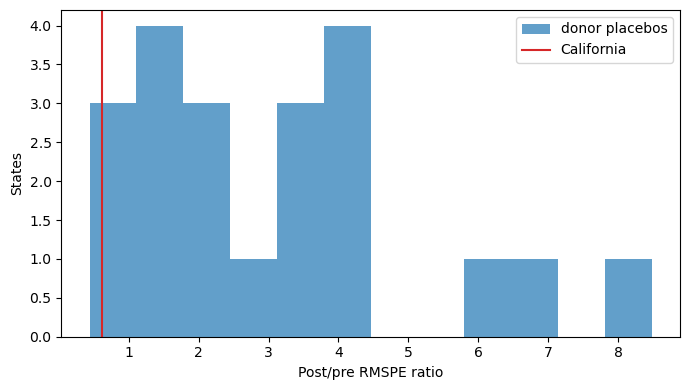

In [9]:
space = synth.placebo_in_space(ca, pool, n_pre=N_PRE, covariates_treated=cov_ca,
                               covariates_donors=cov_donors, covariate_weight=COVARIATE_WEIGHT)
guarded = synth.placebo_in_space(ca, pool, n_pre=N_PRE, max_pre_ratio=5.0, covariates_treated=cov_ca,
                                 covariates_donors=cov_donors, covariate_weight=COVARIATE_WEIGHT)
print(f"California's post/pre RMSPE ratio: {space.treated_ratio:.2f}")
print(f"all {space.n_placebos} donor placebos: rank {space.rank} of {space.n_placebos + 1}, p = {space.p_value:.3f}")
print(f"placebos with pre-period RMSPE within 5x California's ({guarded.n_placebos}): rank {guarded.rank} of {guarded.n_placebos + 1}, p = {guarded.p_value:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(space.donor_ratios, bins=12, color="tab:blue", alpha=0.7, label="donor placebos")
ax.axvline(space.treated_ratio, color="tab:red", label="California")
ax.set_xlabel("Post/pre RMSPE ratio")
ax.set_ylabel("States")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
"""not pre-specified (added after review, 2026-10-23): what size of gap this permutation test could have detected."""
print(ADDED)
n_units = space.n_placebos + 1
max_rank = int(np.floor(PERMUTATION_ALPHA * n_units))
sorted_ratios = np.sort(space.donor_ratios)
need_ratio = float(sorted_ratios[-max_rank])
need_post = need_ratio * fit.pre_rmspe
below = int((space.donor_ratios >= space.treated_ratio).sum())
print(f"California's ratio {space.treated_ratio:.2f} is at or below {below} of {space.n_placebos} donor placebos; rank {space.rank} of {n_units}, p = {space.p_value:.4f}")
print(f"the smallest p-value this test can return is 1/{n_units} = {1 / n_units:.4f}; p at most {PERMUTATION_ALPHA} needs rank {max_rank} or better, "
      f"that is a post/pre ratio above the {max_rank}{'nd' if max_rank == 2 else 'th'}-largest donor ratio, {need_ratio:.2f}")
print(f"with California's pre-period RMSPE of {fit.pre_rmspe:.2f} index points, that is a post-period RMSPE of about {need_post:.1f} index points: "
      f"a persistent gap of roughly {to_thousands(need_post):,.0f} thousand jobs, {100 * need_post / float(np.mean(fit.synthetic[N_PRE:])):.1f}% of the synthetic series")
print(f"California's observed post-period RMSPE is {fit.post_rmspe:.2f} index points; the mean gap is {mean_gap:+.1f} thousand jobs ({mean_pct:+.2f}%), "
      "which is not distinguishable from zero and far below what this test could detect.")

not pre-specified (added after review, 2026-10-23)
California's ratio 0.62 is at or below 20 of 21 donor placebos; rank 21 of 22, p = 0.9545
the smallest p-value this test can return is 1/22 = 0.0455; p at most 0.1 needs rank 2 or better, that is a post/pre ratio above the 2nd-largest donor ratio, 7.10
with California's pre-period RMSPE of 1.28 index points, that is a post-period RMSPE of about 9.1 index points: a persistent gap of roughly 153 thousand jobs, 7.7% of the synthetic series
California's observed post-period RMSPE is 0.80 index points; the mean gap is +9.0 thousand jobs (+0.47%), which is not distinguishable from zero and far below what this test could detect.


In [11]:
"""Falsification 1: how well the synthetic control fits California before the policy."""
FIT_PASS = pre_pct <= FIT_LIMIT_PCT
print(f"FALSIFICATION: pre-period fit | statistic={pre_pct:.3f} | RMSPE as percent of mean pre-period employment, limit {FIT_LIMIT_PCT} | verdict={'PASS' if FIT_PASS else 'FAIL'}")

FALSIFICATION: pre-period fit | statistic=1.277 | RMSPE as percent of mean pre-period employment, limit 3.0 | verdict=PASS


In [12]:
"""Falsification 2: an in-time placebo at 2014-01, before the SB 3 increase (AB 10 steps lie in this window; see Limitations)."""
ca_early, pool_early = indexed(PLACEBO_PRE)          # base: the months used in this fit only
cov_ca_early, cov_donors_early = covariates(PLACEBO_PRE)
early = synth.placebo_in_time(ca_early, pool_early, n_pre=N_PRE, placebo_pre=PLACEBO_PRE,
                              covariates_treated=cov_ca_early, covariates_donors=cov_donors_early,
                              covariate_weight=COVARIATE_WEIGHT)
benchmark = float(np.quantile(space.donor_ratios, 0.90))
TIME_PASS = early.rmspe_ratio <= benchmark
print(f"FALSIFICATION: in-time placebo at 2014-01 | statistic={early.rmspe_ratio:.3f} | post/pre RMSPE ratio over 2014-01..2016-12, limit the 90th percentile of the donor placebo ratios {benchmark:.3f} | verdict={'PASS' if TIME_PASS else 'FAIL'}")
print(f"(placebo-period gap RMSPE {early.post_rmspe:.2f} index points against a fitted-period RMSPE {early.pre_rmspe:.2f})")

FALSIFICATION: in-time placebo at 2014-01 | statistic=4.124 | post/pre RMSPE ratio over 2014-01..2016-12, limit the 90th percentile of the donor placebo ratios 5.839 | verdict=PASS
(placebo-period gap RMSPE 3.82 index points against a fitted-period RMSPE 0.93)


In [13]:
"""Falsification 3: is California's ratio distinguishable from the placebo distribution?"""
PERM_PASS = space.p_value <= PERMUTATION_ALPHA
print(f"FALSIFICATION: permutation test, California against {space.n_placebos} donor placebos | statistic={space.p_value:.4f} | p-value, rank {space.rank}, threshold {PERMUTATION_ALPHA} | verdict={'PASS' if PERM_PASS else 'FAIL'}")

FALSIFICATION: permutation test, California against 21 donor placebos | statistic=0.9545 | p-value, rank 21, threshold 0.1 | verdict=FAIL


In [14]:
"""The decision rule from the plan, applied as written."""
print(f"Mean post-period gap: {mean_gap:+,.1f} thousand jobs ({mean_pct:+.2f}% of the synthetic series); leave-one-out range [{loo['mean post gap'].min():+,.1f}, {loo['mean post gap'].max():+,.1f}].")
plain_gap = to_thousands(float(plain.gap[N_PRE:].mean()))
spread = [mean_gap, plain_gap, float(loo["mean post gap"].min()), float(loo["mean post gap"].max())]
agree = len({np.sign(v) for v in spread}) == 1
print(f"Sign of the mean post-period gap across the headline, the outcomes-only fit and the leave-one-out fits: {'the same' if agree else 'NOT the same'} "
      f"(range {min(spread):+,.1f} to {max(spread):+,.1f} thousand jobs).")
print(f"Effect detected (permutation p at most {PERMUTATION_ALPHA}): {PERM_PASS}.")
print(f"Pre-period fit passed: {FIT_PASS}; in-time placebo passed: {TIME_PASS}.")
if not PERM_PASS:
    print(f"No effect was detected: California's ratio ranks {space.rank} of {space.n_placebos + 1}, which a state with no policy would match often enough.")
if FIT_PASS and TIME_PASS:
    print("Fit and in-time placebo pass: by the plan's rule the design is credible for this donor pool.")
else:
    print("A design check fails: by the plan's rule the gap is descriptive, not an identified effect.")

Mean post-period gap: +9.0 thousand jobs (+0.47% of the synthetic series); leave-one-out range [+15.5, +29.3].
Sign of the mean post-period gap across the headline, the outcomes-only fit and the leave-one-out fits: NOT the same (range -6.5 to +29.3 thousand jobs).
Effect detected (permutation p at most 0.1): False.
Pre-period fit passed: True; in-time placebo passed: True.
No effect was detected: California's ratio ranks 21 of 22, which a state with no policy would match often enough.
Fit and in-time placebo pass: by the plan's rule the design is credible for this donor pool.


## Amendment provenance

The pre-analysis plan was committed once and amended once. This section states what the record shows about the
interval between them. It is reconstructed from the commit log and from this session's own record; **no log or
output of the first executions survives**, and nothing from them is committed.

- **The plan** was committed at 12:45:58 EDT on 2026-10-23, before the notebook existed. It fixed a request window of
  2010-01 to 2019-12 for every series, so post-period months were retrieved whenever any series was.
- **First execution (about 12:47 EDT).** It requested the identifier lookups and then all 66 series for the whole window.
  It stopped in the retrieval cell with "a series has a missing month": the FRED date had been held as a column
  and not as the index, a coding error unrelated to the data. No fit, gap, plot or placebo cell had run, and the
  provenance files it wrote were overwritten by later runs.
- **Second execution (about 12:52 EDT).** After that fix it requested all series again. Code cells 5 to 7 (the fit in levels,
  the outcomes-only fit and the leave-one-out fits) ran to completion in the kernel; the permutation cell stopped with
  "weights did not reach first-order optimality from any start". The run was not saved on failure, so the weights, the
  fit and the post-period gap in levels were never displayed or stored, and the log read afterwards held only the traceback.
  The amendment's own wording, that no gap "had been computed or seen", is corrected here: a levels gap had been
  computed in memory and was not displayed.
- **Diagnosis (about 12:58 EDT).** The 22 outcome series were requested again for the whole window into a temporary
  file. The fitting routine was run once for each donor as a placebo on donors alone, with no output. A printed summary used the
  first 84 months only: California's pre-period mean and the largest donor's (printed by the predictors cell above) and the
  count of months in which California exceeds every donor (also printed above). No post-period value was printed or inspected.
- **Amendment (13:00:27 EDT, 14 minutes 29 seconds after the plan).** The plan was amended in its own commit to fit
  indexed series. No other rescaling was tried first: the index base (each unit's own mean over 2010-01 to 2016-12) and
  the covariate scale of 5 index points were fixed in the amendment without comparing alternatives.
- **After the amendment** the notebook ran twice. After the first amended run's results were read, one line was added to
  the final cell comparing the sign of the mean gap across specifications. It changes no estimate, window, donor, threshold
  or covariate. The second run is the one stored here.

Indexing is a pre-period-only choice and the plan (section 9) anticipated the convex-hull failure that prompted it.
The statements that the plan was committed before any outcome was retrieved, or that the checks were fixed before any outcome
was read, are not true of this notebook, and are corrected here and in the Takeaways.

## Limitations

- **Permutation inference depends on the pool, and has a floor.** With 21 donors the smallest possible p-value is 1/22,
  and the p-value is valid only for the pool as built. The detectability cell prints how large a persistent gap would
  have to be to reach the plan's threshold, and where California's ratio falls. The estimate is not distinguishable
  from zero, and the test could not have detected a gap of the size observed.
- **The sign of the gap is not stable.** The mean gap changes sign across specifications (the predictor-balance cell prints each);
  two donors carry all the weight, and dropping either changes the answer.
- **Convex hull and the predictors.** In levels California exceeds every donor in every pre-period month, so the fit uses
  indexed series. In index space the outcome can be matched, but California's covariates may lie outside the donors' range;
  the balance table says whether they do. A good pre-period fit says how well the weights did, not that the donors are comparable.
- **The earlier minimum-wage steps are inside the sample.** California's AB 10 raised its minimum wage in two steps, in July 2014 and
  January 2016 (as recalled and not verified in this build; the schedule file records only 1 January values and shows the 2014 step as a
  full-year value). Both fall inside the fitting period and the in-time placebo window. The estimand is therefore the start
  of the SB 3 schedule on top of those steps, and the in-time placebo cannot show that the method "does not invent gaps": a
  real wage step lies in its window. The schedule file shows the same value for 2016 and 2017, so it does not record SB 3's first step
  (a rate for larger employers above the file's figure); SB 3 was chaptered in April 2016 for 1 January 2017 (California Senate Bill 3, as recalled, not verified).
- **Anticipation.** SB 3 was chaptered nine months before the first increase. Employers may have responded in the last months
  of the pre-period, which the pre-period fit would not reveal.
- **First of several.** The 2017 step is the first of several scheduled increases, so the estimate describes the schedule's start, not one wage level.
- **Local ordinances.** The state-level schedule does not show local minimum-wage changes. As recalled and not verified in this build,
  some Iowa counties raised their minimum wages in 2016-17 and Louisville and Lexington in Kentucky in 2015-16, and both states are in the donor pool.
- **Different footing for the two ratios.** The in-time placebo's ratio divides a 36-month post RMSPE by a 48-month pre RMSPE; the main ratio
  divides it by an 84-month one. As planned, they are compared against the same donor distribution, which is not like with like.
- **Series.** The outcome is a revised, seasonally adjusted estimate; FRED serves the current revision. The provenance
  records call the retrieval pinned because the window is pinned at both ends; the notebook's metadata says the vintage is not pinned
  because FRED rewrites history. Both are true: a window fixes the reference period, not the revision.
- **Window.** The post-period stops in December 2019, before the pandemic, which is a scope choice rather than a finding.
- **Departure from the pre-analysis plan.** The plan was amended once, in its own dated commit, from levels to indexed series. The amendment
  was written after two executions had stopped and a diagnosis of the pre-period months, not before any outcome was retrieved; the
  amendment-provenance section above states what was and was not seen. The outcome, donor pool, windows, covariates, estimators, checks,
  thresholds and decision rule did not change; this notebook is bound to the amended plan. Everything labelled "not pre-specified" was
  added after review on 2026-10-23, and none of it replaces a result the plan defines.

## Key Takeaways

1. With one treated unit, the weights are the argument: the table says which states stand in for California.
2. A good pre-period fit is necessary, not sufficient; the in-time placebo asks whether the method invents gaps where
   there was no policy, and it can only answer that if no policy step lies in its window, which for California it does.
3. Permutation inference has a floor set by the number of donors, and the notebook reports California's rank and the
   size of gap the test could have detected, not only a gap.
4. Fixing the donor rule, predictors and checks in a plan before the analysis runs is what lets a failed check be reported as a
   finding. Here the plan was amended once after two executions had stopped, and the amendment-provenance section says how.

## Exercises

1. Drop the two covariates and compare the weights table. Which donors enter or leave?
2. Move the in-time placebo to 2013-01 and to 2015-01. How does its ratio compare with the donor placebos?
3. Restrict the placebo distribution to donors whose pre-period RMSPE is within 2 times California's. Does the rank change?
4. Add Washington, which raised its minimum wage in 2016, to the pool. Why would that make the estimate less
   interpretable, and which check would show it?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Abadie, Diamond and Hainmueller (2010), *Synthetic Control Methods for Comparative Case Studies*, Journal of the
  American Statistical Association.
- Abadie (2021), *Using Synthetic Controls: Feasibility, Data Requirements, and Methodological Aspects*, Journal of
  Economic Literature.
- U.S. Bureau of Labor Statistics, Current Employment Statistics (state series republished by FRED).
- U.S. Department of Labor, Wage and Hour Division, state minimum wage history (see `data/policy/minimum_wage/SOURCES.md`).